# Segmenting point clouds into a sphere and planes

## Settings

In [2]:
INPUT_FRAME = None          # None runs all PCD files; otherwise give one filename.
MAX_PLANES = 4              # Initial tests use four; None removes the cap.
PLANE_TOLERANCE_MM = 6.0    # Plane inlier distance, in mm.
MIN_PLANE_FRACTION = 0.03   # Minimum fraction of points needed for a plane.
RANSAC_TRIALS = 350         # Three-point attempts per plane.
RANDOM_SEED = 42            # Keeps random sampling reproducible.
SPHERE_TRIALS = 800         # Four-point sphere attempts.
SPHERE_TOLERANCE_MM = 5.0   # Sphere inlier distance, in mm.

## 1. Reading the PCD file

Only `x`, `y` and `z` and invalid values or without depth (`z <= 0`) are left out.


In [3]:
import math
import numpy as np

def read_pcd(file_path):
    """Read the x, y, z coordinates from an ASCII PCD file."""
    fields = []     # Column names from the FIELDS line, e.g. x y z rgb intensity.
    counts = []     # Number of values per field from the COUNT line (normally 1 each).
    columns = None  # Positions of x, y, z in a data row; set when the header ends.
    rows = []

    with open(file_path, "r") as file:
        for line in file:
            tokens = line.split()

            # Skip empty / comment lines.
            if not tokens or tokens[0].startswith("#"):
                continue

            # Data rows: keep only the x, y, z
            if columns is not None:
                rows.append([float(tokens[i]) for i in columns])
                continue

            # Header lines
            keyword = tokens[0].upper()

            if keyword == "FIELDS":
                fields = tokens[1:]

            elif keyword == "COUNT":
                counts = [int(value) for value in tokens[1:]]

            elif keyword == "DATA":
                # DATA is the last header line
                if len(tokens) < 2 or tokens[1].lower() != "ascii":
                    raise ValueError("Only ASCII PCD files are supported.")

                # Check the coordinates that I need
                if not all(axis in fields for axis in ("x", "y", "z")):
                    raise ValueError("The PCD file must contain the fields x, y and z.")

                # If COUNT is absent
                if not counts:
                    counts = [1] * len(fields)

                # Finding x, y, z indexes -> [0, 1, 2]
                columns = [sum(counts[:fields.index(axis)]) for axis in ("x", "y", "z")]

    if columns is None:
        raise ValueError("No DATA line found: this is not a valid PCD file.")

    points = np.array(rows, dtype=np.float64).reshape(-1, 3)

    # Drop invalid measurements: NaN/inf values and points without depth (z <= 0).
    valid = np.isfinite(points).all(axis=1) & (points[:, 2] > 0)

    return points[valid]

In [4]:
from pathlib import Path

folder = Path.cwd()

if INPUT_FRAME is None:
    frame_paths = sorted(folder.glob("*.pcd"))
else:
    frame_paths = [folder / INPUT_FRAME]

print(f"Selected {len(frame_paths)} frame(s).")

Selected 11 frame(s).


## 2. Distance from a point to a plane

In [ ]:
# A, B and C lie on z = 500 and are not on one line.
A = np.array([10, 20, 500])
B = np.array([30, 20, 500])
C = np.array([10, 50, 500])

# Q is 2 mm away from that plane.
Q = np.array([200, 100, 498])

normal = np.cross(B - A, C - A)
unit_normal = normal / np.linalg.norm(normal)
distance_mm = abs(np.dot(Q - A, unit_normal))

# cutoff
tolerance_mm = 3

print(f"Normal: {normal} mm")
print(f"Unit Normal: {unit_normal} mm")
print(f"Distance to plane: {distance_mm:g} mm")
print(f"Within tolerance: {distance_mm <= tolerance_mm}")

Normal: [  0   0 600] mm
Unit Normal: [0. 0. 1.] mm
Distance to plane: 2 mm
Within tolerance: True


## 3. Plane RANSAC

In [6]:
def find_plane(cloud, tolerance_mm, trials, rng):
    """Find the sampled plane with the most inliers."""
    best_plane = None
    best_mask = np.zeros(len(cloud), dtype=bool)
    best_count = 0

    for _ in range(trials):
        
        # Select the 3 points
        a, b, c = cloud[rng.choice(len(cloud), size=3, replace=False)]
        
        # Calculate the normal 
        normal = np.cross(b - a, c - a)
        length = np.linalg.norm(normal) #
        
        # Must be non-collinear ( not too close points )
        if length < 1e-10:
            continue
        
        normal = normal / length
        offset = normal @ a
        
        # Calculate every point's perpendicular distance to the plane
        mask = np.abs(cloud @ normal - offset) <= tolerance_mm
        
        # How many points satify the range?
        count = np.count_nonzero(mask)
        
        # Save the best found
        if count > best_count:
            best_plane = (normal, offset)
            best_mask = mask
            best_count = count

    return best_plane, best_mask

In [7]:
def segment_planes(points, sphere_mask=None, tolerance_mm=None, max_planes=MAX_PLANES, refine=False):
    """Detectc and labels the planes that RANSAC is able to find"""
    
    if tolerance_mm is None:
        tolerance_mm = PLANE_TOLERANCE_MM
    
    rng = np.random.default_rng(RANDOM_SEED)
    
    plane_labels = np.zeros(len(points), dtype=int) # No planes yet
    
    if sphere_mask is not None:
        plane_labels[sphere_mask] = -1  # Exclude sphere points from the plane search.
    
    # still available for plane detection
    remaining = np.flatnonzero(plane_labels == 0)
    
    planes = []
    min_points = max(3, math.ceil(MIN_PLANE_FRACTION * len(points)))

    # Enough points remain
    while len(remaining) >= min_points and (max_planes is None or len(planes) < max_planes):
        # Use RANSAC for finding a plane
        plane, mask = find_plane(points[remaining], tolerance_mm, RANSAC_TRIALS, rng)
        
        # Count the inliers of that plane
        count = np.count_nonzero(mask)
        
        if count < min_points:
            break
        
        if refine:
            # Use the inliers
            cloud = points[remaining]
            
            normal, offset = refit_plane(cloud[mask])
            refined_mask = np.abs(cloud @ normal - offset) <= tolerance_mm
        
            if np.count_nonzero(refined_mask) >= min_points:
                plane, mask = (normal, offset), refined_mask
        
        # Add the found plane
        planes.append(plane)
        
        # Assign the label
        plane_labels[remaining[mask]] = len(planes)
        
        # Remove the inliers for future estimations
        remaining = remaining[~mask]
        
    return planes, plane_labels

frame_results = {}

for path in frame_paths:
    points = read_pcd(path)
    planes, labels = segment_planes(points)
    frame_results[path.name] = (points, planes, labels)
    
    print(f"{path.name}: {len(points):,} valid points, {len(planes)} planes")

Frame15439.pcd: 217,043 valid points, 4 planes
Frame18031.pcd: 216,702 valid points, 4 planes
Frame4994.pcd: 215,659 valid points, 4 planes
Frame5551.pcd: 217,056 valid points, 4 planes
Frame5922.pcd: 217,028 valid points, 4 planes
Frame7183.pcd: 217,009 valid points, 4 planes
Frame7735.pcd: 217,073 valid points, 4 planes
Frame8078.pcd: 217,088 valid points, 4 planes
Frame9387.pcd: 217,088 valid points, 4 planes
Frame9592.pcd: 217,088 valid points, 4 planes
Frame9876.pcd: 217,080 valid points, 4 planes


## 4. Looking at the plane results

I use OpenCV to draw the labels in two ways: 
- `x/z` against `y/z` for a camera-like view, 
- `z` against `y` for a side view.


### Code

In [8]:
import cv2

# The notebook previews are ordinary OpenCV images. Jupyter displays PNGs
# returned by this method, without adding another plotting library.
class Preview:
    def __init__(self, bgr_image):
        self.bgr_image = bgr_image

    def _repr_png_(self):
        ok, encoded = cv2.imencode(".png", self.bgr_image)
        if not ok:
            raise ValueError("Could not encode preview image")
        return encoded.tobytes()


# These colors are for the early plane-only comparison plots.
# The final PLY uses label_colors(), defined later in the notebook.
PLANE_PREVIEW_COLORS = np.array([
    [31, 119, 180], [174, 199, 232], [255, 127, 14],
    [255, 187, 120], [44, 160, 44], [152, 223, 138],
    [214, 39, 40], [255, 152, 150], [148, 103, 189],
    [197, 176, 213], [140, 86, 75], [196, 156, 148],
    [227, 119, 194], [247, 182, 210], [127, 127, 127],
    [199, 199, 199], [188, 189, 34], [219, 219, 141],
    [23, 190, 207], [158, 218, 229]
], dtype=np.uint8)


def plane_preview_colors(labels):
    rgb = np.full((len(labels), 3), 211, dtype=np.uint8)
    for label in np.unique(labels):
        if label > 0:
            rgb[labels == label] = PLANE_PREVIEW_COLORS[(label - 1) % len(PLANE_PREVIEW_COLORS)]
    return rgb


def plot_panel(points, rgb, view="camera", title="", width=510, height=360, limits=None):
    """Draw a scatter-style view using RGB point colors and an OpenCV canvas."""
    image = np.full((height, width, 3), 255, dtype=np.uint8)
    left, right, top, bottom = 77, width - 18, 40, height - 48
    if view == "camera":
        x, y = points[:, 0] / points[:, 2], points[:, 1] / points[:, 2]
        xlabel, ylabel = "x / z", "y / z"
    elif view == "side":
        x, y = points[:, 2], points[:, 1]
        xlabel, ylabel = "Depth z (mm)", "Height y (mm)"
    else:
        raise ValueError(f"Unknown view: {view}")

    if limits is None:
        xmin, xmax = float(x.min()), float(x.max())
        ymin, ymax = float(y.min()), float(y.max())
    else:
        xmin, xmax, ymin, ymax = limits

    # One scale for both axes (as with aspect='equal' in Matplotlib).
    units_per_pixel = max((xmax - xmin) / max(right - left, 1),
                          (ymax - ymin) / max(bottom - top, 1), 1e-12) * 1.04
    cx, cy = (xmin + xmax) / 2, (ymin + ymax) / 2
    sx = np.rint((x - cx) / units_per_pixel + (left + right) / 2).astype(np.int32)
    sy = np.rint((top + bottom) / 2 - (y - cy) / units_per_pixel).astype(np.int32)
    inside = (sx >= left) & (sx <= right) & (sy >= top) & (sy <= bottom)
    colors_bgr = np.asarray(rgb, dtype=np.uint8)[:, ::-1]

    # Leave sphere pixels on top of the background and plane measurements.
    yellow = np.all(np.asarray(rgb) == [255, 255, 0], axis=1)
    for choose in (inside & ~yellow, inside & yellow):
        image[sy[choose], sx[choose]] = colors_bgr[choose]

    cv2.rectangle(image, (left, top), (right, bottom), (170, 170, 170), 1)
    cv2.putText(image, title, (left, 24), cv2.FONT_HERSHEY_SIMPLEX,
                0.55, (45, 45, 45), 1, cv2.LINE_AA)
    cv2.putText(image, xlabel, ((left + right) // 2 - 42, height - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.41, (70, 70, 70), 1, cv2.LINE_AA)
    # Rotate the y-axis label, so it cannot overlap the plot title.
    font = cv2.FONT_HERSHEY_SIMPLEX
    text_size, baseline = cv2.getTextSize(ylabel, font, 0.40, 1)
    label_strip = np.full((text_size[1] + baseline + 8,
                           text_size[0] + 12, 3), 255, dtype=np.uint8)
    cv2.putText(label_strip, ylabel, (5, text_size[1] + 3), font,
                0.40, (70, 70, 70), 1, cv2.LINE_AA)
    label_strip = cv2.rotate(label_strip, cv2.ROTATE_90_COUNTERCLOCKWISE)
    label_y = (top + bottom - label_strip.shape[0]) // 2
    image[label_y:label_y + label_strip.shape[0],
          3:3 + label_strip.shape[1]] = label_strip

    # Axis values help make the plots useful for comparing different frames.
    for fraction in (0.0, 0.5, 1.0):
        xt = int(left + fraction * (right - left))
        yt = int(bottom - fraction * (bottom - top))
        value_x = cx + (xt - (left + right) / 2) * units_per_pixel
        value_y = cy + ((top + bottom) / 2 - yt) * units_per_pixel
        cv2.line(image, (xt, bottom), (xt, bottom + 4), (120, 120, 120), 1)
        cv2.line(image, (left - 4, yt), (left, yt), (120, 120, 120), 1)
        fmt = ".2f" if view == "camera" else ".0f"
        cv2.putText(image, format(value_x, fmt), (xt - 18, bottom + 18),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.32, (90, 90, 90), 1, cv2.LINE_AA)
        cv2.putText(image, format(value_y, fmt), (24, yt + 4),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.32, (90, 90, 90), 1, cv2.LINE_AA)
    return image


def combine_panels(panels, title="", columns=2, legend=None):
    """Arrange OpenCV panels with an optional color legend."""
    if not panels:
        raise ValueError("No panels")
    panel_h, panel_w = panels[0].shape[:2]
    rows = math.ceil(len(panels) / columns)
    gap, margin, title_space = 12, 12, 37
    legend_width = 210 if legend else 0
    width = margin * 2 + columns * panel_w + (columns - 1) * gap + legend_width
    height = margin * 2 + title_space + rows * panel_h + (rows - 1) * gap
    result = np.full((height, width, 3), 255, dtype=np.uint8)
    cv2.putText(result, title, (margin + 8, 27), cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (30, 30, 30), 2, cv2.LINE_AA)
    for index, panel in enumerate(panels):
        y0 = margin + title_space + (index // columns) * (panel_h + gap)
        x0 = margin + (index % columns) * (panel_w + gap)
        result[y0:y0 + panel_h, x0:x0 + panel_w] = panel
    if legend:
        x0 = width - legend_width + 10
        y0 = margin + title_space + 18
        cv2.putText(result, "Labels", (x0, y0 - 12), cv2.FONT_HERSHEY_SIMPLEX,
                    0.48, (60, 60, 60), 1, cv2.LINE_AA)
        for k, (name, rgb_color) in enumerate(legend):
            y = y0 + k * 25
            cv2.rectangle(result, (x0, y), (x0 + 13, y + 13),
                          tuple(int(v) for v in rgb_color[::-1]), -1)
            cv2.putText(result, str(name), (x0 + 21, y + 11),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.42, (55, 55, 55), 1, cv2.LINE_AA)
    return result

### Plots

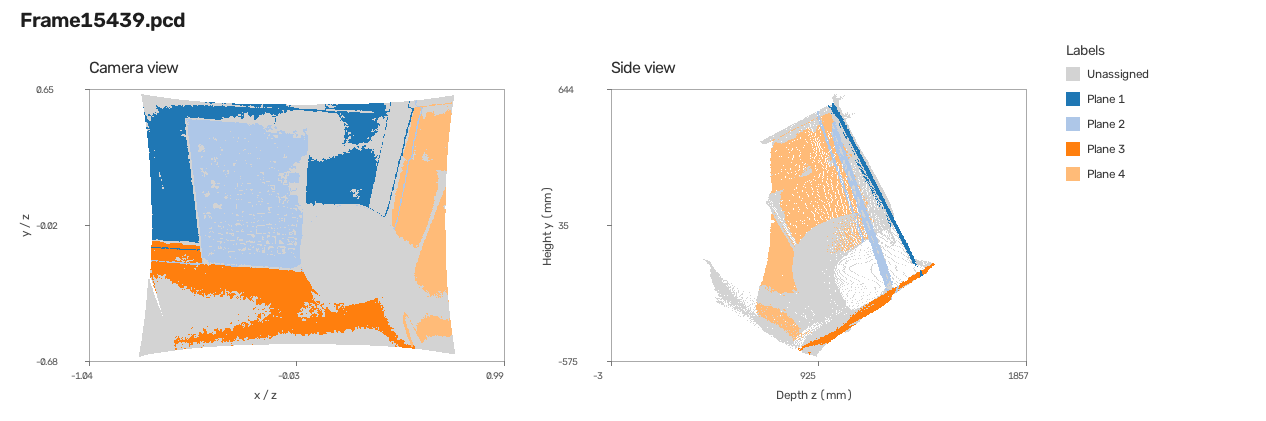

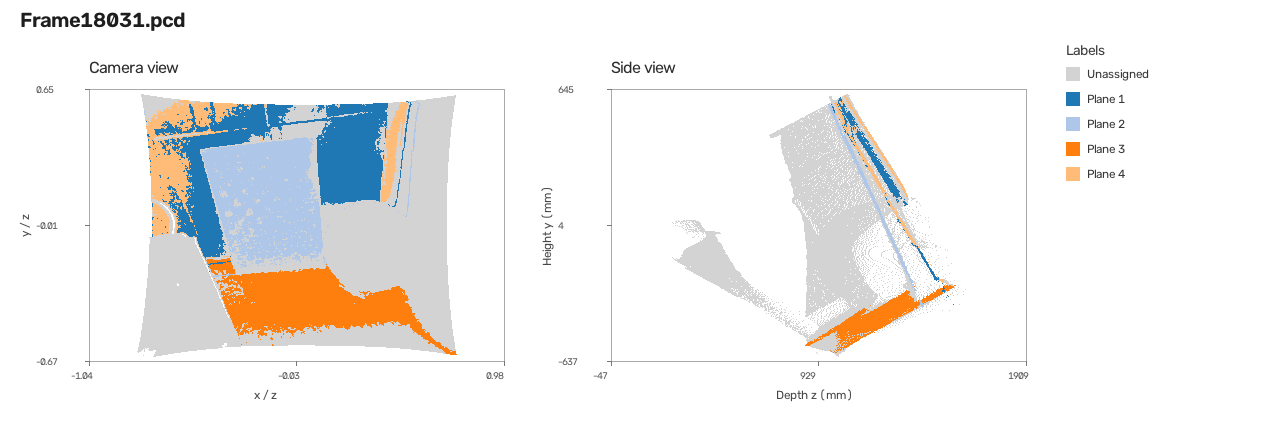

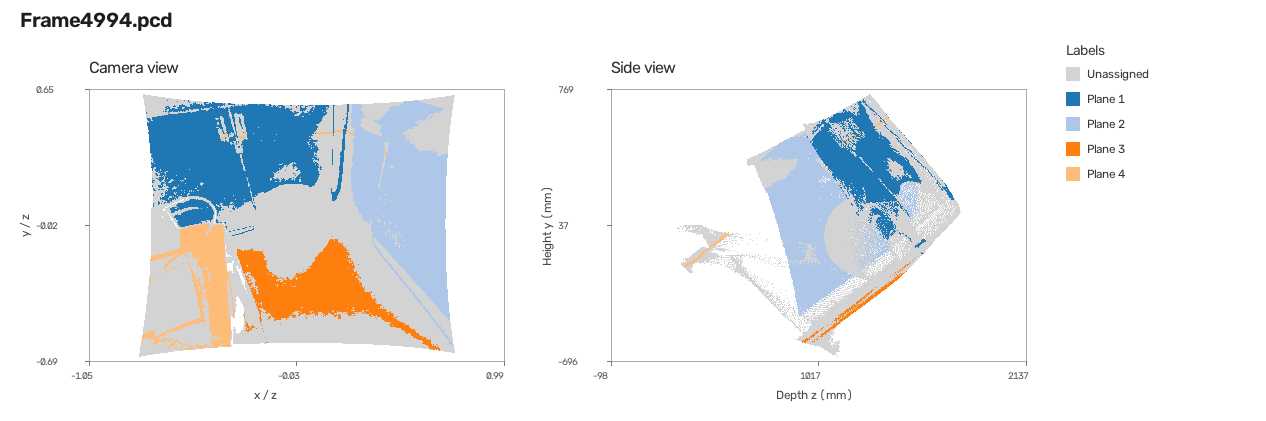

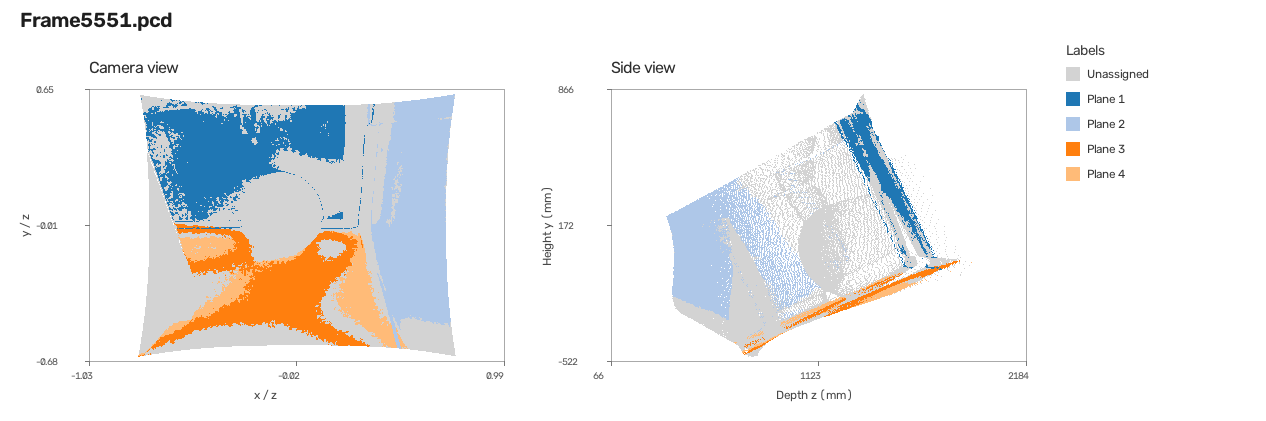

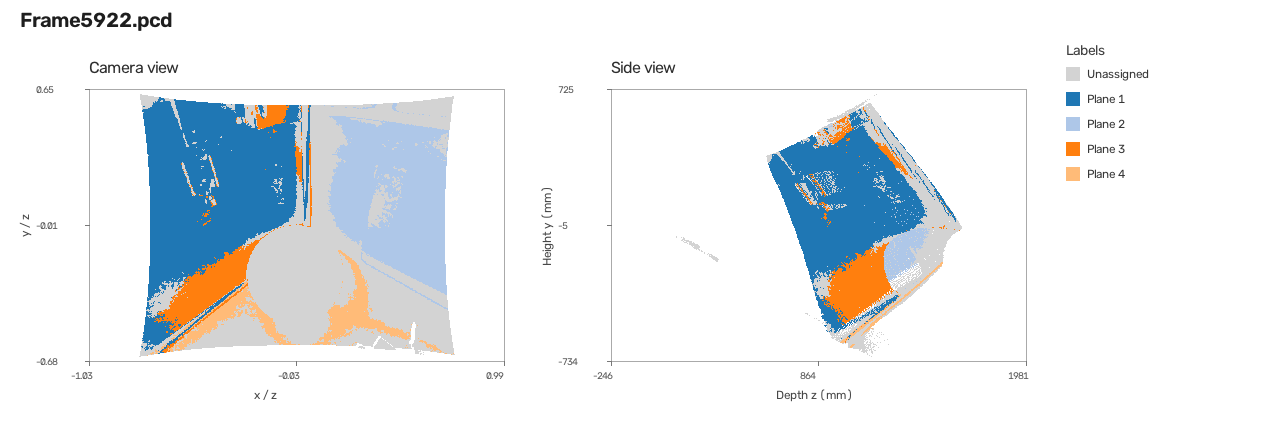

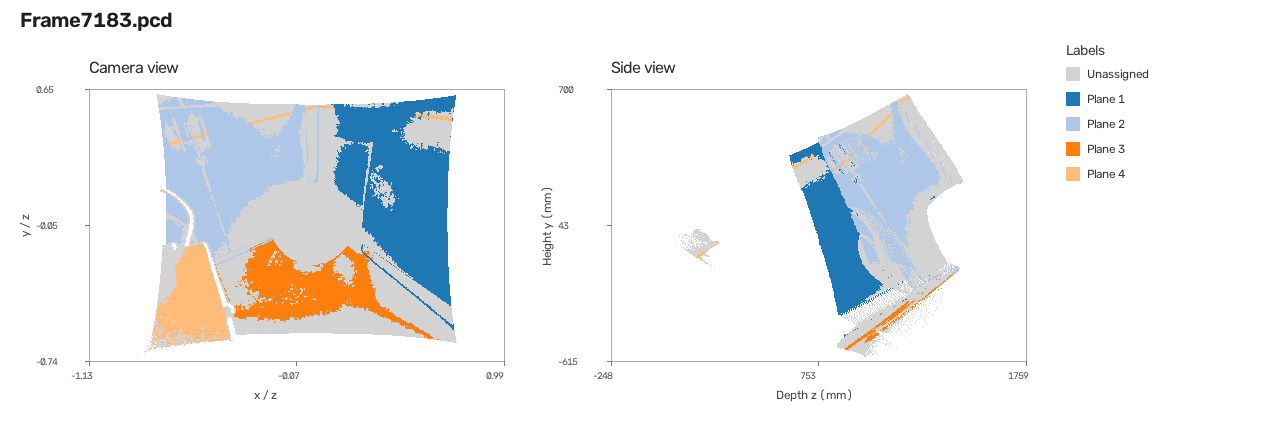

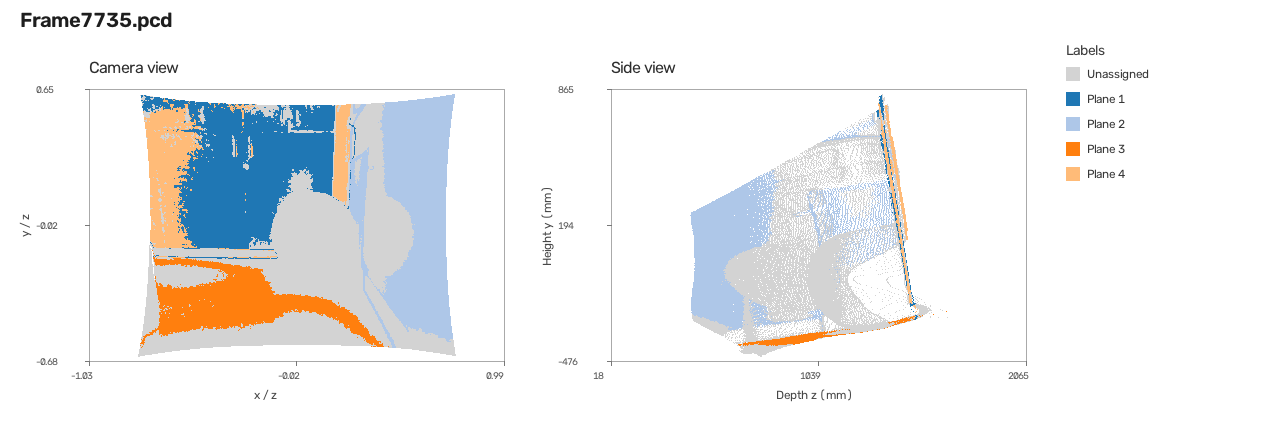

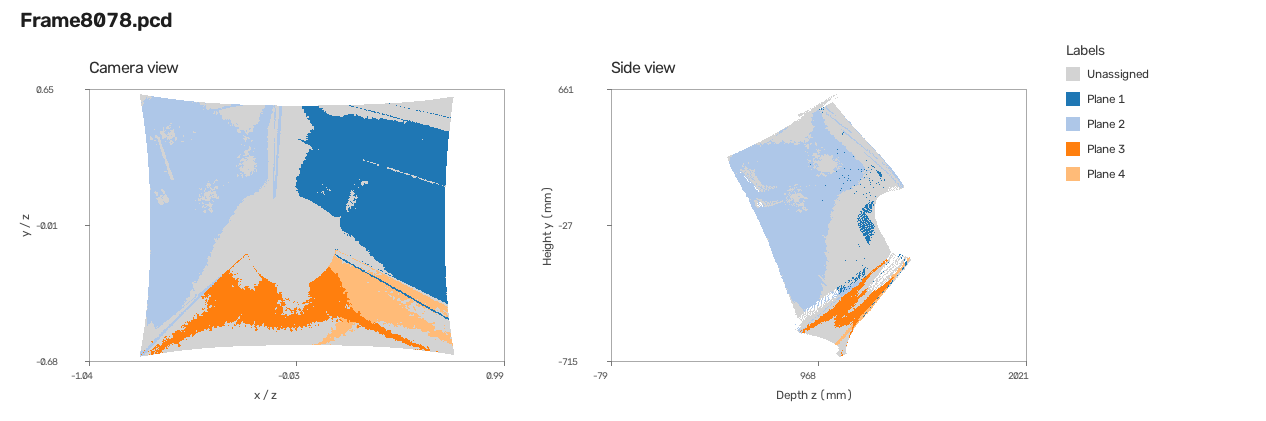

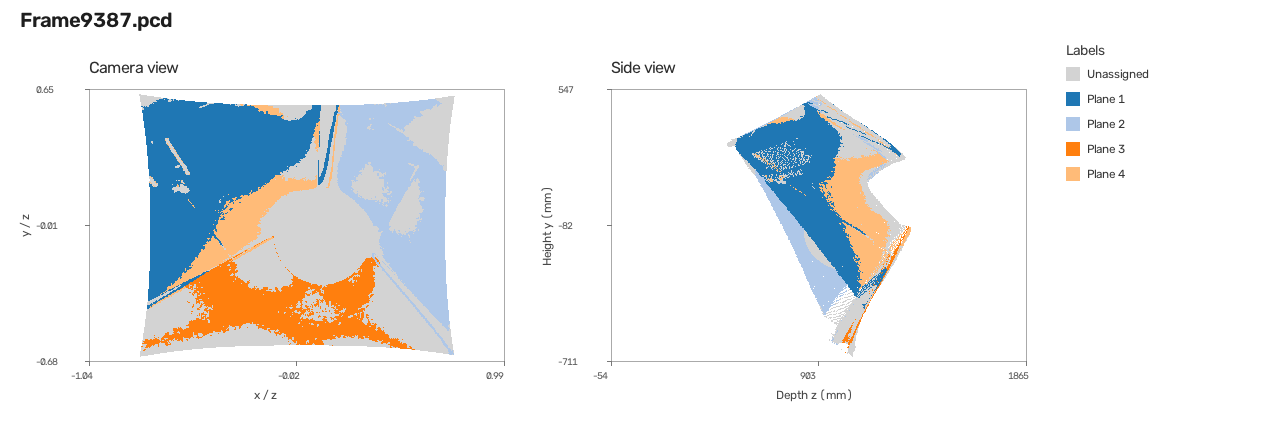

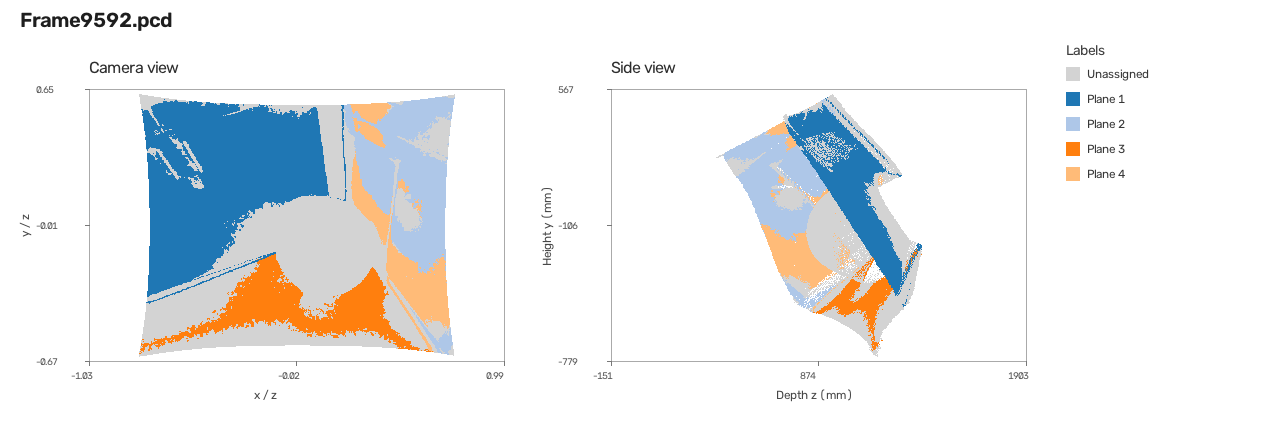

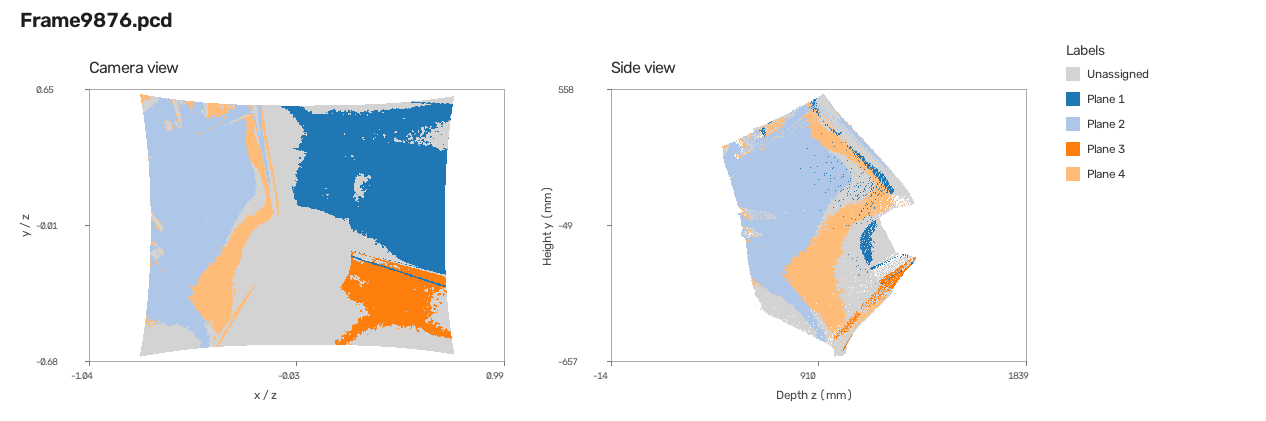

In [9]:
for filename, (points, planes, plane_labels) in frame_results.items():
    rgb = plane_preview_colors(plane_labels)
    views = [plot_panel(points, rgb, "camera", "Camera view"),
             plot_panel(points, rgb, "side", "Side view")]
    legend = [("Unassigned", np.array([211, 211, 211], dtype=np.uint8))]
    legend += [(f"Plane {i}", PLANE_PREVIEW_COLORS[(i - 1) % 20])
               for i in range(1, len(planes) + 1)]
    display(Preview(combine_panels(views, filename, legend=legend)))

## 5. Sphere

In [25]:
def sphere_from_four(sample):
    """Calculate the center and radius"""
    
    origin = sample[0]
    delta = sample[1:] - origin

    try:
        # 2 * [ x2-x1  y2-y1  z2-z1 ] | [ ( x2^2+y2^2+z2^2 ) - ( x2^2+y2^2+z2^2 )]
        shift = np.linalg.solve(2 * delta, np.sum(delta ** 2, axis=1))
    except np.linalg.LinAlgError: # If it's not invertible
        return None
    
    return origin + shift, np.linalg.norm(shift)

# Test with a known 5 mm sphere.
sample = np.array([[15, 20, 500], [10, 25, 500], [10, 20, 505], [5, 20, 500]])
center, radius = sphere_from_four(sample)

print(f"Center: {center} mm, radius: {radius:g} mm")

Center: [ 10.  20. 500.] mm, radius: 5 mm


## 6. Sphere RANSAC
- Only points from its neighborhood.
- reject spheres that are too large relative to the scene

In [11]:
def visible_sphere_inliers(points, center, radius, tolerance_mm):
    offsets = points - center
    
    # radial error
    errors = np.abs(np.linalg.norm(offsets, axis=1) - radius)
    
    # Assume the camera is at the coordinate origin.
    facing_camera = np.sum(offsets * points, axis=1) <= 0
    
    return (errors <= tolerance_mm) & facing_camera

def refine_sphere(inliers, center, radius):
    if len(inliers) < 4:
        return center, radius

    # [1, -2x, -2y, -2z] * [x0^2+y0^2+z0^2-R^2, x0, y0, z0] = -(x^2+y^2+z^2)
    A = np.column_stack((np.ones(len(inliers)), -2 * inliers))
    b = -np.sum(inliers ** 2, axis=1)

    # [k, x0, y0, z0]
    solution = np.linalg.pinv(A) @ b

    new_center = solution[1:]
    radius_squared = new_center @ new_center - solution[0]
    
    if radius_squared <= 0:
        return center, radius

    return new_center, np.sqrt(radius_squared)

def find_sphere(points, tolerance_mm=SPHERE_TOLERANCE_MM):
    rng = np.random.default_rng(RANDOM_SEED)
    sample = points[rng.choice(len(points), min(6000, len(points)), replace=False)]
    scene_width = np.linalg.norm(np.ptp(sample, axis=0))
    best_count = 0
    best = None
    
    for _ in range(SPHERE_TRIALS):
        # I choose an anchor
        anchor = sample[rng.integers(len(sample))]
        
        # I look for 4 points near that anchor, but not too far away
        nearby = sample[np.linalg.norm(sample - anchor, axis=1) < scene_width / 10]
    
        if len(nearby) < 4:
            continue
        
        sphere = sphere_from_four(nearby[rng.choice(len(nearby), 4, replace=False)])
    
        if sphere is None:
            continue
        
        center, radius = sphere
    
        # Reject excessively large spheres
        if radius > scene_width / 4:
            continue
        
        count = np.count_nonzero(visible_sphere_inliers(sample, center, radius, tolerance_mm))
    
        if count > best_count:
            best_count = count
            best = sphere

    if best is None:
        raise ValueError("Could not fit a sphere to this frame.")
   
    center, radius = best
   
    # Refit using the full-cloud inliers.
    initial_mask = visible_sphere_inliers(points, center, radius, tolerance_mm)
    center, radius = refine_sphere(points[initial_mask], center, radius)
    final_mask = visible_sphere_inliers(points, center, radius, tolerance_mm)
   
    return center, radius, final_mask


In [12]:
sphere_results = {}

for filename, (points, _, _) in frame_results.items():
    center, radius, mask = find_sphere(points)
    sphere_results[filename] = (center, radius, mask)
    print(f"{filename}: radius {radius:.1f} mm, {mask.sum():,} sphere points")

Frame15439.pcd: radius 216.0 mm, 18,783 sphere points
Frame18031.pcd: radius 211.3 mm, 15,898 sphere points
Frame4994.pcd: radius 212.2 mm, 10,676 sphere points
Frame5551.pcd: radius 235.1 mm, 14,358 sphere points
Frame5922.pcd: radius 210.0 mm, 17,931 sphere points
Frame7183.pcd: radius 196.9 mm, 11,560 sphere points
Frame7735.pcd: radius 231.8 mm, 14,670 sphere points
Frame8078.pcd: radius 203.2 mm, 13,414 sphere points
Frame9387.pcd: radius 210.6 mm, 15,538 sphere points
Frame9592.pcd: radius 214.3 mm, 17,556 sphere points
Frame9876.pcd: radius 210.5 mm, 17,156 sphere points


### Check the detected sphere

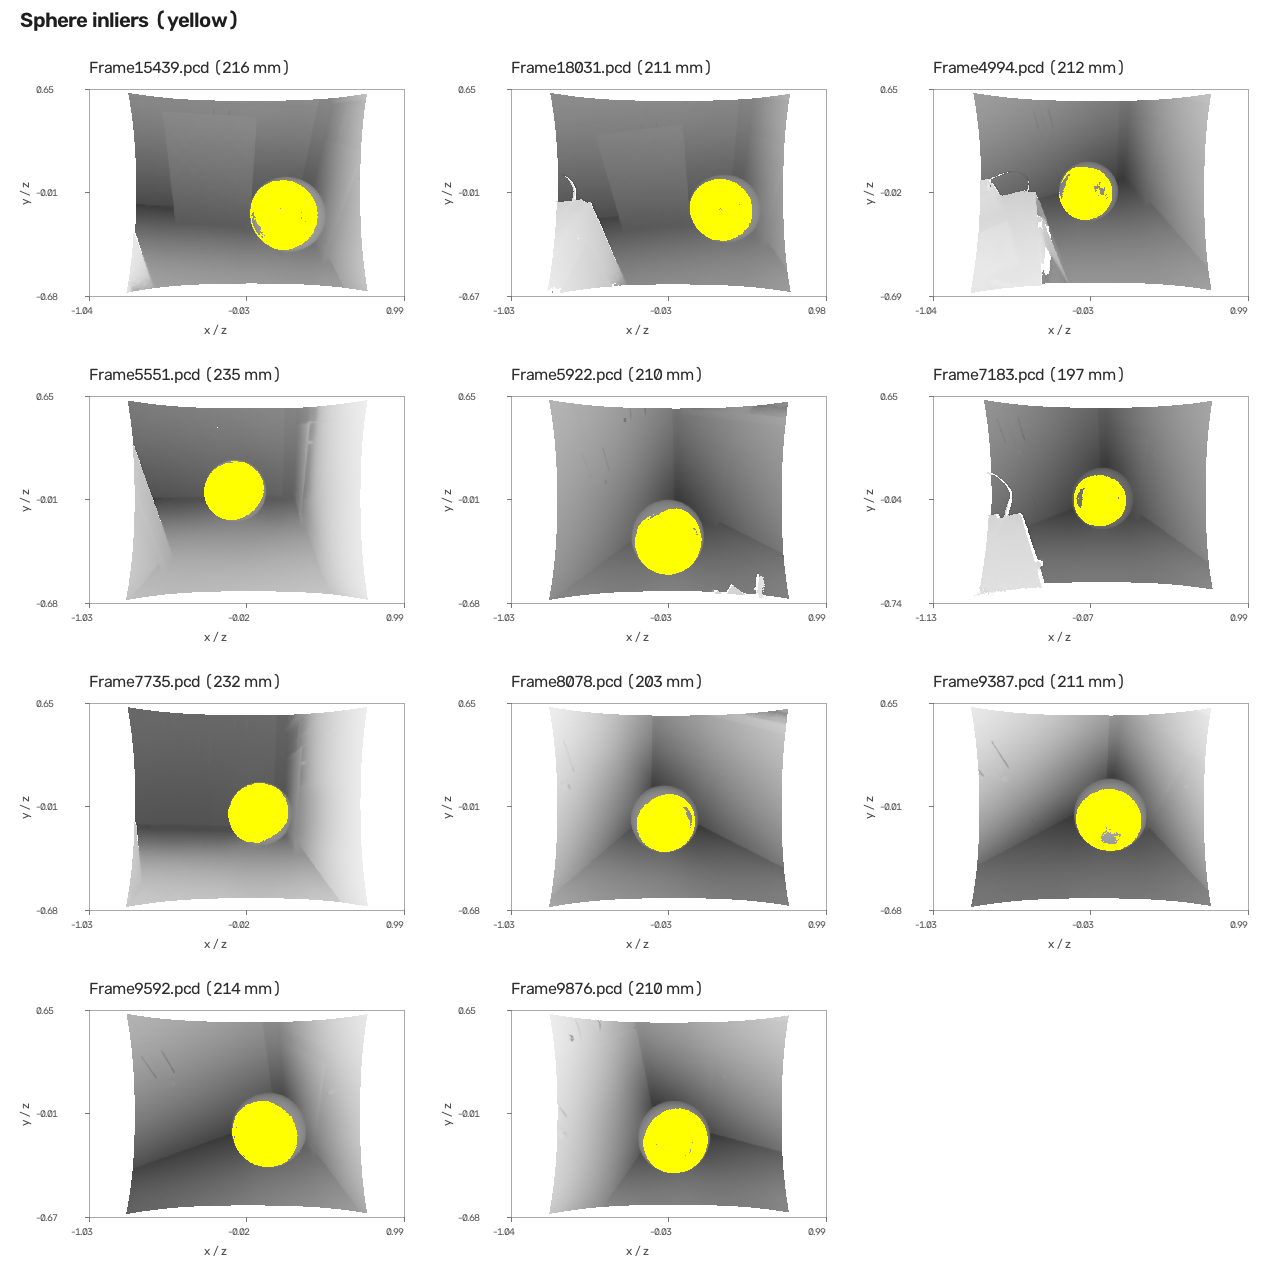

In [13]:
# Each panel shows the same camera projection with the sphere in yellow.
sphere_panels = []
for filename, (points, _, _) in frame_results.items():
    center, radius, mask = sphere_results[filename]
    z = points[:, 2]
    scaled_depth = (z - z.min()) / max(np.ptp(z), 1e-12)
    grey = (238 - scaled_depth * 180).astype(np.uint8)
    rgb = np.repeat(grey[:, None], 3, axis=1)
    rgb[mask] = [255, 255, 0]
    sphere_panels.append(plot_panel(points, rgb, "camera",
                                   f"{filename} ({radius:.0f} mm)",
                                   width=410, height=295))
display(Preview(combine_panels(sphere_panels, "Sphere inliers (yellow)", columns=3)))

## 7. Put the sphere and planes together

In [14]:
from colorsys import hsv_to_rgb

def label_colors(plane_count):
    # Label 0 is grey; -1 indexes the last palette entry (yellow).
    palette = [[160, 160, 160]]
    for i in range(plane_count):
        hue = (0.6 + i * 0.618) % 1
        palette.append([round(255 * v) for v in hsv_to_rgb(hue, 0.8, 0.85)])
    palette.append([255, 255, 0])
    return np.array(palette, dtype=np.uint8)

combined_results = {}
for filename, (points, _, _) in frame_results.items():
    _, _, sphere_mask = sphere_results[filename]
    planes, labels = segment_planes(points, sphere_mask)
    colors = label_colors(len(planes))[labels]
    combined_results[filename] = (planes, labels, colors)

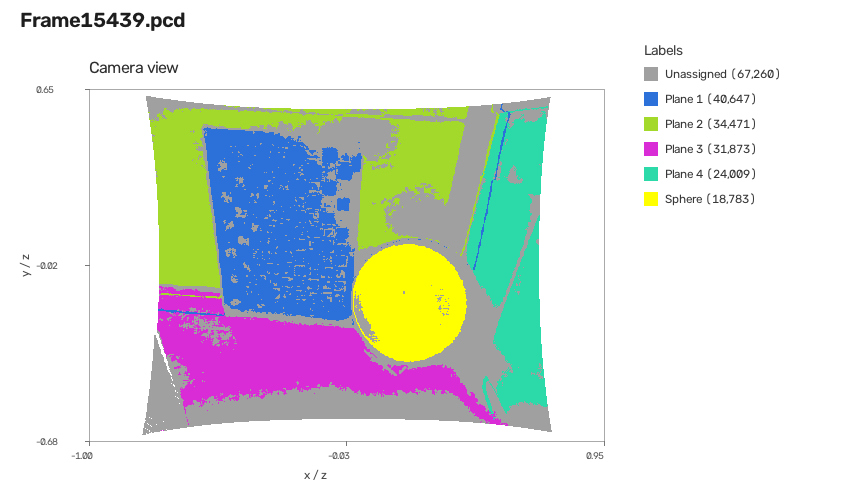

In [15]:
filename = next(iter(combined_results))
points = frame_results[filename][0]
planes, labels, colors = combined_results[filename]
legend = []
for label in [0, *range(1, len(planes) + 1), -1]:
    count = int(np.count_nonzero(labels == label))
    if not count:
        continue
    name = {-1: "Sphere", 0: "Unassigned"}.get(label, f"Plane {label}")
    rgb = label_colors(len(planes))[label]
    legend.append((f"{name} ({count:,})", rgb))
view = plot_panel(points, colors, "camera", "Camera view", width=610, height=440)
display(Preview(combine_panels([view], filename, columns=1, legend=legend)))

### Comparing 3 mm and 6 mm for planes

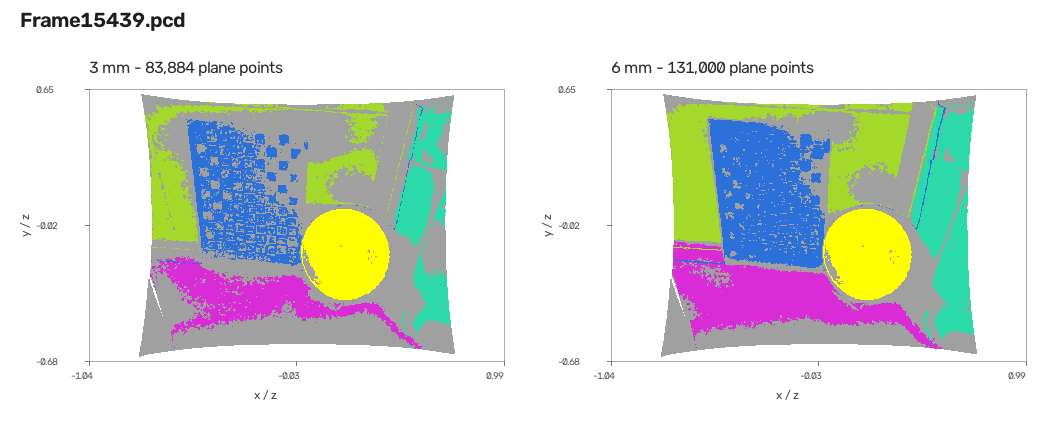

In [16]:
# Compare the two cutoffs on the same points and with the same axis limits.
points = frame_results[filename][0]
sphere_mask = sphere_results[filename][2]
views = []

for tolerance in (3.0, 6.0):
    models, trial_labels = segment_planes(points, sphere_mask, tolerance_mm=tolerance)
    rgb = label_colors(len(models))[trial_labels]
    assigned = np.count_nonzero(trial_labels > 0)
    views.append(plot_panel(points, rgb, "camera",
                            f"{tolerance:g} mm - {assigned:,} plane points"))
display(Preview(combine_panels(views, filename)))

In [17]:
# Count how much of each frame gets a plane label.
print(f"{'Frame':<17} {'3 mm':>8} {'6 mm':>8}")
for name, (cloud, _, _) in frame_results.items():
    sphere_mask = sphere_results[name][2]
    coverage = []
    for tolerance in (3.0, 6.0):
        _, labels = segment_planes(cloud, sphere_mask, tolerance_mm=tolerance)
        coverage.append(100 * np.mean(labels > 0))
    print(f"{name:<17} {coverage[0]:7.1f}% {coverage[1]:7.1f}%")

Frame                 3 mm     6 mm
Frame15439.pcd       38.6%    60.4%
Frame18031.pcd       37.8%    59.2%
Frame4994.pcd        39.9%    56.6%
Frame5551.pcd        43.4%    58.8%
Frame5922.pcd        47.0%    62.4%
Frame7183.pcd        41.6%    55.2%
Frame7735.pcd        42.7%    58.7%
Frame8078.pcd        47.9%    63.7%
Frame9387.pcd        42.1%    62.5%
Frame9592.pcd        44.6%    64.8%
Frame9876.pcd        47.7%    62.8%


## 8. Refit the planes

In [18]:
def refit_plane(inliers):
    # Centroid
    center = inliers.mean(axis=0) 
    
    # P - Centroid
    centered = inliers - center 
    
    # covariance matrix -> principal directions the point cloud varies
    _, axes = np.linalg.eigh(centered.T @ centered)
    
    # least variation
    normal = axes[:, 0]  # min eig. Value
    
    return normal, normal @ center

### Estimate

In [19]:
def estimate_surface_noise(points):
    """Estimate a noise scale from small local patches."""
    rng = np.random.default_rng(RANDOM_SEED)
    sample = points[rng.choice(len(points), min(len(points), 10000), replace=False)]
    
    if len(sample) < 4:
        raise ValueError("At least four valid points are required.")
    
    scales = []
    
    for anchor in sample[rng.choice(len(sample), min(64, len(sample)), replace=False)]:
        distances = np.sum((sample - anchor) ** 2, axis=1)
        k = min(40, len(sample))
        
        patch = sample[np.argpartition(distances, k - 1)[:k]]
        normal, offset = refit_plane(patch)
        residuals = patch @ normal - offset
        
        # Calculate the Mean Absolute Deviation
        mad = np.median(np.abs(residuals - np.median(residuals)))
        scales.append(1.4826 * mad)
    
    precision = np.finfo(float).eps * max(1.0, np.max(np.abs(sample))) * 32
    
    return max(np.median(scales), precision)

In [20]:
def segment_frame(points):
    noise = estimate_surface_noise(points)
    plane_tolerance = 10 * noise
    sphere_tolerance = 3.5 * noise
    _, _, sphere_mask = find_sphere(points, tolerance_mm=sphere_tolerance)
    planes, labels = segment_planes(points, sphere_mask, tolerance_mm=plane_tolerance,
                                   max_planes=None, refine=True)
    colors = label_colors(len(planes))[labels]
    
    return labels, colors, plane_tolerance, sphere_tolerance

for name, (cloud, _, _) in frame_results.items():
    labels, _, plane_tol, sphere_tol = segment_frame(cloud)
    print(f"{name}: plane {plane_tol:.2f} mm, sphere {sphere_tol:.2f} mm, "
          f"{labels.max()} plane candidates, {(labels == -1).sum():,} sphere points")

Frame15439.pcd: plane 15.43 mm, sphere 5.40 mm, 4 plane candidates, 19,505 sphere points
Frame18031.pcd: plane 14.93 mm, sphere 5.22 mm, 5 plane candidates, 16,057 sphere points
Frame4994.pcd: plane 14.23 mm, sphere 4.98 mm, 5 plane candidates, 10,652 sphere points
Frame5551.pcd: plane 15.05 mm, sphere 5.27 mm, 6 plane candidates, 14,738 sphere points
Frame5922.pcd: plane 12.92 mm, sphere 4.52 mm, 4 plane candidates, 17,551 sphere points
Frame7183.pcd: plane 13.65 mm, sphere 4.78 mm, 5 plane candidates, 10,946 sphere points
Frame7735.pcd: plane 12.57 mm, sphere 4.40 mm, 5 plane candidates, 14,324 sphere points
Frame8078.pcd: plane 10.90 mm, sphere 3.81 mm, 4 plane candidates, 11,997 sphere points
Frame9387.pcd: plane 12.87 mm, sphere 4.50 mm, 4 plane candidates, 14,908 sphere points
Frame9592.pcd: plane 13.37 mm, sphere 4.68 mm, 4 plane candidates, 17,161 sphere points
Frame9876.pcd: plane 10.53 mm, sphere 3.68 mm, 5 plane candidates, 14,821 sphere points


---


## 9. Exporting `main.py`

The notebook is for experimenting and checking plots. The next cells define the PLY writer and build a standalone script from the functions above.

Example command:

```bash
python main.py Frame4994.pcd Frame4994.ply
```


In [21]:
def write_ply(path, points, colors):
    header = ("ply\nformat ascii 1.0\n"
              f"element vertex {len(points)}\n"
              "property double x\nproperty double y\nproperty double z\n"
              "property uchar red\nproperty uchar green\nproperty uchar blue\nend_header")
    np.savetxt(path, np.column_stack((points, colors)), header=header, comments="",
               fmt="%.12g %.12g %.12g %d %d %d")

def main():
    import argparse
    parser = argparse.ArgumentParser(description="Color the sphere and planes in an ASCII PCD.")
    parser.add_argument("input_pcd")
    parser.add_argument("output_ply")
    args = parser.parse_args()
    points = read_pcd(args.input_pcd)
    _, colors, plane_tol, sphere_tol = segment_frame(points)
    write_ply(args.output_ply, points, colors)
    print(f"Saved {len(points):,} points. Plane tolerance {plane_tol:.2f} mm, "
          f"sphere tolerance {sphere_tol:.2f} mm.")

In [22]:
import inspect

functions = [read_pcd, refit_plane, estimate_surface_noise, find_plane, segment_planes,
             sphere_from_four, refine_sphere, visible_sphere_inliers, find_sphere, label_colors,
             segment_frame, write_ply, main]
imports = "import math\nfrom colorsys import hsv_to_rgb\n\nimport numpy as np"
settings = ["MAX_PLANES", "PLANE_TOLERANCE_MM", "MIN_PLANE_FRACTION", "RANSAC_TRIALS",
            "RANDOM_SEED", "SPHERE_TRIALS", "SPHERE_TOLERANCE_MM"]
constants = "\n".join(f"{name} = {globals()[name]!r}" for name in settings)
source = "\n\n\n".join([imports, constants, *(inspect.getsource(fn).rstrip() for fn in functions),
                         'if __name__ == "__main__":\n    main()'])
(folder / "main.py").write_text(source + "\n", encoding="utf-8")

10829